<a href="https://colab.research.google.com/github/villsydican/machine-learning-project/blob/main/Chart_annalysis_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import io
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from google.auth import default
from PIL import Image

# 1. Authenticate & Build Drive API
auth.authenticate_user()
creds, _ = default()
drive_service = build('drive', 'v3', credentials=creds)

# 2. Path to your manually created dataset folder
output_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'

def download_and_slice(file_id, file_name, rows, cols, label_mapping, prefix):
    print(f"📥 Downloading: {file_name}...")
    request = drive_service.files().get_media(fileId=file_id)
    local_path = f"/tmp/{file_id}.jpg"

    with open(local_path, 'wb') as fh:
        downloader = MediaIoBaseDownload(fh, request)
        done = False
        while not done:
            status, done = downloader.next_chunk()

    img = Image.open(local_path).convert('RGB')
    w, h = img.size
    cell_w, cell_h = w / cols, h / rows
    count = 0

    for r in range(rows):
        for c in range(cols):
            label = label_mapping.get((r, c))
            if not label:
                continue
            crop = img.crop((
                int((c + 0.08) * cell_w), int((r + 0.18) * cell_h),
                int((c + 0.92) * cell_w), int((r + 0.78) * cell_h)
            )).resize((128, 128))

            save_path = os.path.join(output_dir, label, f"{prefix}_r{r}_c{c}.jpg")
            crop.save(save_path)
            count += 1

    print(f"✅ Sliced & sorted {count} tiles from {file_name}")

# 3. Process each sheet into your manual folders
download_and_slice(
    "1BViimj3mJ-lnL-M79d0QkfOv56AX2BrK", "Bullish candlestick pattern.jpg",
    3, 3, {(r, c): 'buy' for r in range(3) for c in range(3)}, "bullish_9"
)

download_and_slice(
    "1Vkj8OA80pGCvJO8sIN1QY_MP9jEHB1yA", "Candlestick signals",
    2, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'sell', (0,3): 'sell', (1,0): 'buy', (1,1): 'buy', (1,2): 'buy', (1,3): 'hold'}, "signals_8"
)

download_and_slice(
    "1GLPPljf91i74zHnMfGtUixI4g8CoIyZr", "TRADING PSYCHOLOGY.jpg",
    4, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'buy', (0,3): 'sell', (1,0): 'sell', (1,1): 'buy', (1,2): 'sell', (1,3): 'sell', (2,0): 'buy', (2,1): 'sell', (2,2): 'sell', (2,3): 'sell', (3,0): 'buy', (3,1): 'sell', (3,2): 'buy', (3,3): 'sell'}, "psych_16"
)

download_and_slice(
    "1kj43Dk9YyS9stuEWuG70bDoAbOY7PpmO", "Take Your Binary Options Trading",
    4, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'buy', (0,3): 'buy', (1,0): 'sell', (1,1): 'buy', (1,2): 'sell', (1,3): 'sell', (2,0): 'buy', (2,1): 'sell', (2,2): 'buy', (2,3): 'sell', (3,0): 'buy', (3,1): 'sell', (3,2): 'buy', (3,3): 'sell'}, "binary_16"
)

download_and_slice(
    "15sUVHLacRm-3-AzpLHP0CwswZl22p2bD", "Trade Smarter with Our Binary Options Strategy PDF.jpg",
    3, 5, {(r, c): 'sell' for r in range(3) for c in range(5)}, "bearish_15"
)

print("\n🎉 Population complete! Folder counts:")
for cls in ['buy', 'sell', 'hold']:
    print(f"📂 {cls}/ -> {len(os.listdir(os.path.join(output_dir, cls)))} images")

In [2]:
#Generating the images using python
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

output_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
for cls in ['buy', 'sell', 'hold']:
  os.makedirs(os.path.join(output_dir, cls), exist_ok=True)

def render_candles(candles, save_path, dark_mode=False):
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  bg_color = '#12161c' if dark_mode else '#ffffff'
  bull_color = '#26a69a' if dark_mode else '#16a34a'
  bear_color = '#ef5350' if dark_mode else '#dc2626'
  fig.patch.set_facecolor(bg_color)
  ax.set_facecolor(bg_color)
  for idx, (o, h, l, c) in enumerate(candles):
    color = bull_color if c >= o else bear_color
    #Wick generation
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    #Body generation
    lower = min(o, c)
    height = max(abs(c - o), 0.15) #Minimum visible thickness for Doji
    react = Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(react)
  all_lows = [x[2] for x in candles]
  all_highs = [x[1] for x in candles]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(-0.7, len(candles) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  fig.savefig(save_path, dpi=100, facecolor=bg_color)
  plt.close(fig)

# Pattern Generators (each building 4 trend candles + key signal candle)
def generate_buy_pattern():
  pattern_type = random.choice(['hammer', 'bullish_engulfing', 'morning_star', 'three_white_soldiers'])
  price = random.uniform(50, 100)
  candles = []
  if pattern_type == 'hammer':
    # 4 bearish downtrend candles + long lower-wick hammer
    for _ in range (4):
      o = price
      c = o - random.uniform(1.2, 3.0)
      h = o + random.uniform(0.2, 1.0)
      l = c - random.uniform(0.2, 1.0)
      candles.append((o, h, l, c))
      price = c
    o = price
    c = o + random.uniform(0.4, 1.2)
    h = c + random.uniform(0.0, 0.3)
    l = o - random.uniform(3.5, 6.5)
    candles.append ((o, h, l, c))
  elif pattern_type == 'bullish_engulfing':
    # 3 downtrend + 1 small red + 1 large green engulfing candle
    for _ in range (3):
      o = price
      c = o - random.uniform(1.0, 2.5)
      candles.append((o, o + 0.6, c - 0.6, c))
      price = c
    o1 = price
    c1 = o1 - random.uniform(0.8, 1.6)
    candles.append((o1, o1 + 0.4, c1 - 0.4, c1))
    o2 = c1 - random.uniform(0.1, 0.4)
    c2 = o1 + random.uniform(1.0, 2.5)
    candles.append((o2, c2 + 0.5, o2 - 0.4, c2))

  elif pattern_type == 'morning_star':
    # 2 downtrend + 1 big red + 1 small star + big green
    for _ in range (2):
      o = price
      c = o - random.uniform(1.0, 2.0)
      candles.append ((o, o + 0.5, c - 0.5, c))
      price = c
    o1, c1 = price, price - random.uniform(2.5, 4.0)
    candles.append((o1, o1 + 0.4, c1 - 0.4, c1))
    o2 = c1 - random.uniform(0.2, 0.6)
    c2 = o2 + random.uniform(-0.3, 0.3)
    candles.append((o2, max(o2, c2) + 0.7, min(o2, c2) - 0.7, c2))
    o3 = max(o2, c2) + 0.2
    c3 = o1 - random.uniform(0.0, 0.8)
    candles.append((o3, c3 + 0.5, o3 - 0.3, c3))
  else: # drawing three white soldiers
    for _ in range (2):
      o = price
      c = o - random.uniform(1.2, 2.5)
      candles.append((o, o + 0.5, c - 0.5, c))
      price = c
    for _ in range (3):
      o = price + random.uniform(0.1, 0.4)
      c = o + random.uniform(1.8, 3.2)
      candles.append((o, c + 0.4, o - 0.3, c))
      price = c

  return candles

def generate_sell_pattern():
  pattern_type = random.choice(['shooting_star', 'bearish_engulfing', 'evening_star', 'three_black_crows'])
  price = random.uniform(50, 100)
  candles = []

  if pattern_type == 'shooting_star':
    for _ in range(4):
      o = price
      c = o + random.uniform(1.2, 3.0)
      h = c + random.uniform(0.2, 1.0)
      l = o - random.uniform(0.2, 1.0)
      candles.append((o, h, l, c ))
      price = c
    o = price
    c  = o - random.uniform(0.4, 1.2)
    h = o + random.uniform(3.5, 6.5)
    l = c - random.uniform(0.0, 0.3)
    candles.append((o, h, l, c))
  elif pattern_type == 'bearish_engulfing' :
    for _ in range (3):
      o = price
      c = o + random.uniform(1.0, 2.5)
      candles.append((o, c + 0.6, o - 0.6, c))
      price = c
    o1 =  price
    c1 = o1 + random.uniform(0.8, 1.6)
    candles.append((o1, c1 + 0.4, o1 - 0.4, c1 ))
    o2 = c1 + random.uniform(0.1, 0.4)
    c2 = o1 - random.uniform(1.0, 2.5)
    candles.append((o2, o2 + 0.4, c2 - 0.5, c2))
  elif pattern_type == 'evening_star':
    for _ in range(2):
      o = price
      c = o + random.uniform(1.0, 2.0)
      candles.append((o, c + 0.5, o - 0.5, c)) # Fixed undefined o1 to o
      price = c
    o1, c1 = price, price + random.uniform(2.5, 4.0)
    candles.append((o1, c1 + 0.4, o1 - 0.4, c1))
    o2 = c1 + random.uniform(0.2, 0.6)
    c2 = o2 + random.uniform(-0.3, 0.3)
    candles.append((o2, max(o2, c2) + 0.7, min(o2, c2) - 0.7, c2))
    o3 = min(o2, c2) - 0.2
    c3 = o1 + random.uniform(0.0, 0.8)
    candles.append((o3, o3 + 0.3, c3 - 0.5, c3))
  else : # three_black_crows
    for _ in range (2):
      o = price
      c = o + random.uniform(0.1, 0.4)
      candles.append((o, o + 0.3, c - 0.4, c))
      price = c
    for _ in range(3):
      o = price - random.uniform(0.1, 0.4)
      c = o - random.uniform(1.8, 3.2)
      candles.append((o, o + 0.3, c - 0.4, c))
      price = c
  return candles

# Generating images for holding or equilibrium patterns
# Sideways consolidation with dojis and Spinning tops
def generate_hold_pattern():
  base_price = random.uniform(50, 100 )
  candles = []
  for _ in range(5):
    o = base_price + random.uniform(-0.8, 0.8)
    c = o + random.uniform(-0.4, 0.4)
    h = max(o, c) + random.uniform(0.8, 2.2)
    l = min(o, c) - random.uniform(0.8, 2.2)
    candles.append((o, h, l, c))
  return candles

# Generating 200 images per class
samples_per_class = 1000
print (f"Generating {samples_per_class * 3} synthetic candlestick images.....")

for i in range (samples_per_class):
  dark = random.choice([True, False]) # Mixing the light and dark trading themes
  render_candles(generate_buy_pattern(), os.path.join(output_dir, 'buy', f'synth_buy_{i:03d}.png'), dark_mode=dark)
  render_candles(generate_sell_pattern(), os.path.join(output_dir, 'sell', f'synth_sell_{i:03d}.png'), dark_mode=dark)
  render_candles(generate_hold_pattern(), os.path.join(output_dir, 'hold', f'synth_hold_{i:03d}.png'), dark_mode=dark)
print ("===========================")
print ("\n Synthetic dataset generation complet!! Updated Folde Total: ")
for cls in ['buy', 'sell', 'hold']:
  total = len(os.listdir(os.path.join(output_dir, cls)))
  print(f"{cls}/ -> {total} total images")

Generating 3000 synthetic candlestick images.....

 Synthetic dataset generation complet!! Updated Folde Total: 
buy/ -> 1000 total images
sell/ -> 1000 total images
hold/ -> 1000 total images


In [3]:
#MODEL TRAINING AND VALIDATION
import tensorflow as tf
data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
batch_size = 16
img_height, img_width = 128, 128
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset = "training",
    seed = 123,
    image_size = (img_height, img_width),
    batch_size = batch_size,
    label_mode = 'categorical'#converting the data into one-hot-encoded structure




)
#loading the validation Dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed = 123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode = 'categorical'#converting the data into one-hot-encoded structure
)
class_names = train_ds.class_names
print (f"\n Detected Model Classes : {class_names}")


Found 3000 files belonging to 3 classes.
Using 2400 files for training.
Found 3000 files belonging to 3 classes.
Using 600 files for validation.

 Detected Model Classes : ['buy', 'hold', 'sell']


In [4]:
#MODEL TRAINING AND EXECUTION
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
    layers.Conv2D(32, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')#output layer


])
#Compling the model
model.compile(
    optimizer='adam',
    loss = 'categorical_crossentropy',
    metrics=['accuracy']
)
#Printing the summary of the model layers and tool parameters
model.summary()



/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
#Training and testing the model performances
epochs = 15
print (f"Starting training for {epochs} epochs....\n")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)
print ("\Training completed!!!!")
model_path = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'
model.save(model_path)
print(f"Model saved to: {model_path} Successfully")

Starting training for 15 epochs....

Epoch 1/15


<>:9: SyntaxWarning: invalid escape sequence '\T'
<>:9: SyntaxWarning: invalid escape sequence '\T'
/tmp/ipykernel_5081/364429844.py:9: SyntaxWarning: invalid escape sequence '\T'
  print ("\Training completed!!!!")


150/150 ━━━━━━━━━━━━━━━━━━━━ 69s 446ms/step - accuracy: 0.9542 - loss: 0.1245 - val_accuracy: 1.0000 - val_loss: 3.7975e-06
Epoch 2/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 78s 422ms/step - accuracy: 1.0000 - loss: 1.4608e-05 - val_accuracy: 1.0000 - val_loss: 5.1458e-07
Epoch 3/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 83s 427ms/step - accuracy: 1.0000 - loss: 6.9627e-06 - val_accuracy: 1.0000 - val_loss: 2.2510e-07
Epoch 4/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 65s 432ms/step - accuracy: 1.0000 - loss: 6.5316e-06 - val_accuracy: 1.0000 - val_loss: 5.1657e-08
Epoch 5/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 70s 464ms/step - accuracy: 1.0000 - loss: 1.1501e-06 - val_accuracy: 1.0000 - val_loss: 3.5763e-08
Epoch 6/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 82s 546ms/step - accuracy: 0.9925 - loss: 0.0286 - val_accuracy: 0.9983 - val_loss: 0.0094
Epoch 7/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 102s 679ms/step - accuracy: 1.0000 - loss: 9.4089e-05 - val_accuracy: 1.0000 - val_loss: 3.8345e-08
Epoch 8/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 143s 687m

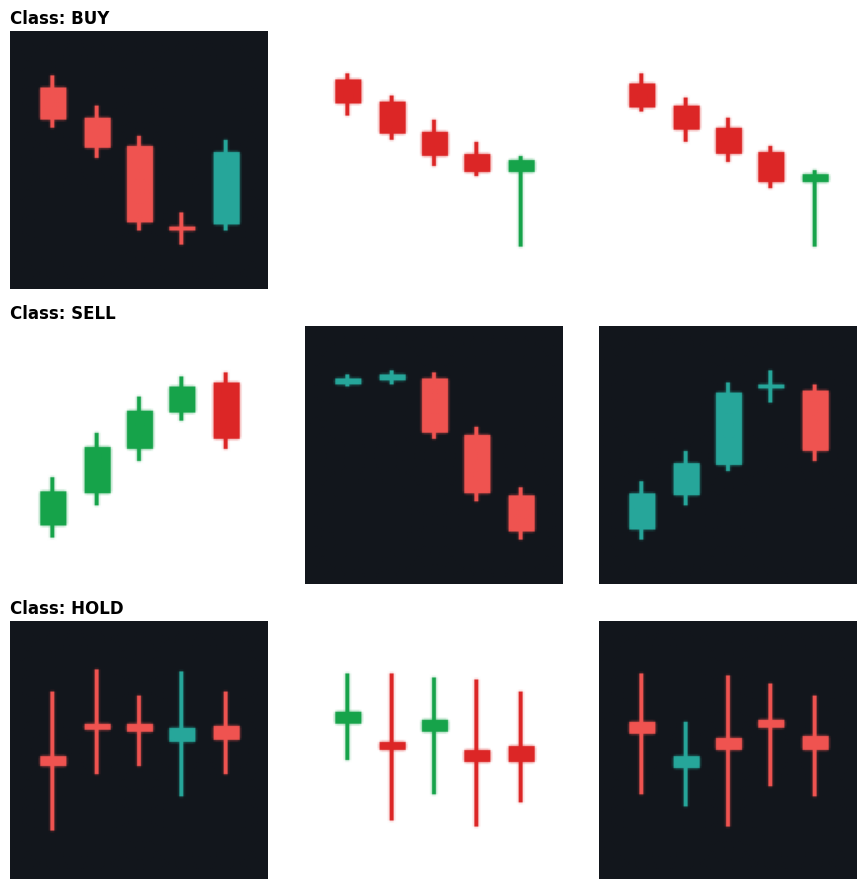

In [8]:
#Visualizing the data generated
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
classes = ['buy', 'sell', 'hold']

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row_idx, cls in enumerate(classes):
  cls_folder = os.path.join(data_dir, cls)
  sample_files = random.sample(os.listdir(cls_folder), 3)
  for col_idx, file_name in enumerate(sample_files):
    img_path = os.path.join(cls_folder, file_name)
    img = mpimg.imread(img_path)
    ax = axes[row_idx, col_idx]
    ax.imshow(img)
    ax.axis('off')
    if col_idx == 0:
      ax.set_title(f"Class: {cls.upper()}", fontsize=12, fontweight='bold', loc='left')
plt.tight_layout()
plt.show()

In [14]:
#Feeding the fetched data into the model
import tensorflow as tf
from tensorflow.keras.models import load_model

model = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'
model = load_model(model)

print ("Model loaded successfully")
class_names = ['buy', 'hold', 'sell']
if df_stock is not None and not df_stock.empty and len(df_stock) >= 5:
  recent_candles = df_stock.tail(5)
  candles_tuple = [(row['Open'], row['High'], row['Low'], row['Close']) for _, row in recent_candles.iterrows()]
  #REndering into memory buffer
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')
  for idx, (o, h, l, c) in enumerate(candles_tuple):
    color = '#16a34a' if c>= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    lower = min(o, c)
    height = max(abs(c - o), 0.15)
    rect = patches.Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(rect)
  all_lows = [x[2] for x in candles_tuple]
  all_highs = [x[1] for x in candles_tuple]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(-0.7, len(candles_tuple) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  buf = io.BytesIO()
  fig.savefig(buf, format='png', dpi=100, facecolor='#ffffff')
  buf.seek(0)
  plt.close(fig)

  #Predicting the data to buy/sell/hold
  img = tf.keras.utils.load_img(buf, target_size=(128, 128))
  img_array = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)

  preds = model.predict(img_array) [0]
  best_idx = preds.argmax()







Model loaded successfully


In [10]:
import os
from getpass import getpass
ALPHA_VANTAGE_API_KEY= getpass("Enter your Alpha API Key: ")


Enter your Alpha API Key: ··········


In [42]:
#LOADING LIVE MARKET DATA FROM ALPHA_VANTAGE_STOCK_MARKET
import io
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import yfinance as yf

#Fetching live market data
def fetch_alpha_vantage_data(ticker):
  if not ALPHA_VANTAGE_API_KEY:
    raise ValueError("Alpha Vantage API key not found. Please set the environment variable 'ALPHA_VANTAGE_API_KEY'.")



  print (f"Fetching the data for {ticker}...")
  url = "https://www.alphavantage.co/query"
  params = {
      'function': 'TIME_SERIES_DAILY',
      'symbol': ticker,
      'interval': '5min',
      'outputsize': 'compact',
      'apikey': ALPHA_VANTAGE_API_KEY
  }
  response = requests.get(url, params=params, timeout=30)
  data = response.json()
  time_series = data.get('Time Series (Daily)')


  if time_series is None:
    print("ALpha Vantage did not return market Data")
    print(data.get("Note") or data.get("Information") or data.get("Error Message"))

    return None

  df = pd.DataFrame.from_dict(time_series, orient='index')
  df.index = pd.to_datetime(df.index)
  df.sort_index(inplace = True)

  df.rename(columns={
        '1. open': 'Open',
        '2. high': 'High',
        '3. low': 'Low',
        '4. close': 'Close',
        '5. volume': 'Volume'
    }, inplace=True)
  for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
      df[col] = pd.to_numeric(df[col], errors='coerce')
  return df.dropna()

  #Fetching the data from yfinace for testing
def fetch_yfinance_data(ticker):
    print (f"Fetching the data for {ticker}............")
    df = yf.download(ticker, period="1y", interval="1d", auto_adjust=True, progress=False)
    if df.empty:
        print(f"No data found for {ticker}")
        return None
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[['Open', 'High', 'Low', 'Close', 'Volume']]
    df = df.dropna()
    print("Yahoo Finance downloaded sucefully..")
    return df

#MERGING THE TWO DATAS FROM ALPHA VANTAGE AND YFINACE

def fetch_market_data(ticker):
  df = fetch_alpha_vantage_data(ticker)

  if df is not None and  not df.empty:
    print("Using ALpha Vantage data...")
    return df
  print ("Trying Yahoo finance instead.....")

  df = fetch_yfinance_data(ticker)
  if df is not None and not df.empty:
    print ("Using Yahoo finance data..")
    return df

  print (f"No market data available for {ticker}..")


#image rendering and saving (Making the telegram function to include even the images)


def render_and_save_tile(candles, path):
  """
  Renders the last 5 candles into a clean 128 * 128 in_memory
  ready to be sent as a photo attachment via telegram"""
  os.makedirs(os.path.dirname(save_path), exist_ok=True)
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)

  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')
  for idx, (o, h, l, c) in enumerate(candles):
    color = '#16a34a' if c >= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    rect = patches.Rectangle(
        (idx - 0.28, min(o, c)),
        0.56,
        max(abs(c - o), 0.15),
        facecolor = color,
        edgecolor=color,
        zorder = 2
    )
    ax.add_patch(rect)
  price_range = max(x[1] for x in candles) - min(x[2] for x in candles)
  pad =price_range * 0.15 + 0.5
  ax.set_ylim(min(x[2] for x in candles) - pad, max(x[1] for x in candles) + pad)
  ax.set_xlim(0.5, len(candles) - 0.5)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  fig.savefig(path, format='png', dpi=100, facecolor='#ffffff')
  plt.close("all")






In [43]:
#HISTORICAL LABELLING OF DATA
import yfinance as yf

import os

# Stocks to process
watchlist = ["MSFT"]

# Reset the counter every time this cell runs
total_generated = 0

# Create the three output folders
for folder in ["buy", "hold", "sell"]:
    os.makedirs(os.path.join(output_dir, folder), exist_ok=True)

# Process each stock
for ticker in watchlist:

    # Fetch data ONCE
    df_stock = fetch_market_data(ticker)

    if df_stock is None or len(df_stock) < 10:
        print(f"Insufficient data for {ticker}")
        continue

    source_counts = {"buy": 0, "hold": 0, "sell": 0}

    print(f"\nProcessing {ticker}")
    print("Rows fetched:", len(df_stock))

    # Generate historical samples
    for i in range(5, len(df_stock) - 3):

        # Five-candle historical window
        window = df_stock.iloc[i-5:i]

        current_close = float(window.iloc[-1]["Close"])
        future_close = float(df_stock.iloc[i+3]["Close"])

        # Calculate percentage movement
        pct_change = (future_close - current_close) / current_close

        # Determine label
        if pct_change > 0.005:
            label = "buy"

        elif pct_change < -0.005:
            label = "sell"

        else:
            label = "hold"

        # Convert candles into the format required by render_candles
        candles_tuple = list(
            window[["Open", "High", "Low", "Close"]]
            .itertuples(index=False, name=None)
        )

        # Save image in the correct folder
        save_path = os.path.join(
            output_dir,
            label,
            f"{ticker}_{label}_{i}.png"
        )

        render_and_save_tile(candles_tuple, save_path)

        # Update counters
        source_counts[label] += 1
        total_generated += 1

    # Display results
    print("\nLABEL COUNTS")
    print("BUY:", source_counts["buy"])
    print("HOLD:", source_counts["hold"])
    print("SELL:", source_counts["sell"])
    print("TOTAL:", sum(source_counts.values()))

print("\nTOTAL IMAGES GENERATED:", total_generated)


Fetching the data for MSFT...
Using ALpha Vantage data...

Processing MSFT
Rows fetched: 100

LABEL COUNTS
BUY: 51
HOLD: 6
SELL: 35
TOTAL: 92

TOTAL IMAGES GENERATED: 92


In [44]:
print("OUTPUT DIRECTORY:")
print(os.path.abspath(output_dir))

print("\nDIRECTORY EXISTS:", os.path.exists(output_dir))

for label in ["buy", "hold", "sell"]:
    folder = os.path.join(output_dir, label)

    print(f"\n{label.upper()} FOLDER:")
    print("Path:", os.path.abspath(folder))
    print("Exists:", os.path.exists(folder))

    if os.path.exists(folder):
        files = os.listdir(folder)
        print("Total files:", len(files))
        print("First 5 files:", files[:5])

OUTPUT DIRECTORY:
/content/drive/MyDrive/asset_real_dataset

DIRECTORY EXISTS: True

BUY FOLDER:
Path: /content/drive/MyDrive/asset_real_dataset/buy
Exists: True
Total files: 51
First 5 files: ['MSFT_buy_69.png', 'MSFT_buy_17.png', 'MSFT_buy_23.png', 'MSFT_buy_87.png', 'MSFT_buy_36.png']

HOLD FOLDER:
Path: /content/drive/MyDrive/asset_real_dataset/hold
Exists: True
Total files: 6
First 5 files: ['MSFT_hold_75.png', 'MSFT_hold_79.png', 'MSFT_hold_6.png', 'MSFT_hold_80.png', 'MSFT_hold_51.png']

SELL FOLDER:
Path: /content/drive/MyDrive/asset_real_dataset/sell
Exists: True
Total files: 35
First 5 files: ['MSFT_sell_33.png', 'MSFT_sell_53.png', 'MSFT_sell_74.png', 'MSFT_sell_83.png', 'MSFT_sell_93.png']


In [45]:
for label in ['buy', 'hold', 'sell']:
  folder = os.path.join(output_dir, label)
  images = [f for f in os.listdir(folder) if f.endswith('.png')]
  print(f"{label.upper()}: {len(images)}")


BUY: 51
HOLD: 6
SELL: 35


In [46]:
#Folder creation for separate the live data from the synthetic data
output_dir = "/content/drive/MyDrive/asset_real_dataset"
for label in["buy", "hold", "sell"]:
  os.makedirs(os.path.join(output_dir, label), exist_ok=True)

In [49]:
df_stock = fetch_alpha_vantage_data("MSFT")
print ("Data shape:", df_stock.shape if df_stock is not None else None)
print("Number of rows:", len(df_stock) if df_stock is not None else 0)
if df_stock is not None:
  print(df_stock.head())
  print (df_stock.tail())


Fetching the data for MSFT...
Data shape: (100, 5)
Number of rows: 100
               Open    High     Low   Close    Volume
2026-06-30  371.030  374.15  367.45  373.02  44945696
2026-07-01  380.825  388.83  374.89  384.28  48065801
2026-07-02  384.480  392.20  383.70  390.49  42194409
2026-07-06  387.040  389.15  381.22  386.74  34224543
2026-07-07  392.490  395.57  388.22  388.84  29297524
               Open    High     Low   Close    Volume
2026-11-12  521.100  529.66  520.00  523.00  18644017
2026-11-13  519.745  526.42  513.82  523.88  26189242
2026-11-16  525.090  527.95  516.82  517.99  30218641
2026-11-17  514.565  515.64  496.51  506.24  27992837
2026-11-18  505.710  510.44  501.08  508.29  21337767


In [50]:
#Checking the data distribution
print("Dataset shape: ", df_stock.shape)
print("\nLatest market data:")
print(df_stock.tail(10))
print ("\nGenerated images:")
for label in ['buy', 'hold', 'sell']:
  folder = os.path.join(output_dir, label)
  total = len(os.listdir(folder))
  print(label.upper(), ":", len(os.listdir(folder)))

Dataset shape:  (100, 5)

Latest market data:
               Open    High       Low    Close    Volume
2026-11-05  554.935  557.62  532.6750  535.930  42507933
2026-11-06  525.690  538.33  524.4700  530.610  26956423
2026-11-09  544.485  548.28  538.6996  545.180  25337411
2026-11-10  542.975  544.19  526.3650  533.160  26940880
2026-11-11  534.235  534.76  518.4500  521.125  29076795
2026-11-12  521.100  529.66  520.0000  523.000  18644017
2026-11-13  519.745  526.42  513.8200  523.880  26189242
2026-11-16  525.090  527.95  516.8200  517.990  30218641
2026-11-17  514.565  515.64  496.5100  506.240  27992837
2026-11-18  505.710  510.44  501.0800  508.290  21337767

Generated images:
BUY : 51
HOLD : 6
SELL : 35


In [51]:
#Notification tab
import io
import smtplib
from email.mime.text import MIMEText
from email.mime.multipart import MIMEMultipart
from email.mime.image import MIMEImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import requests
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
import time
import yfinance as yf
import os
from getpass import getpass


#USing telegram for model configuration and getting the news
TELEGRAM_TOKEN = getpass("ENTER YOUR TELEGRAM TOKEN: ").strip().strip('"').strip("'")
CHAT_ID = getpass("ENTER YOUR TELEGRAm CHAT ID: ").strip().strip('"').strip("'")

CONFIDENCE_THRESHOLD = 70.0

#Tracking the alerts to avoid the repetitions
last_sent_signals ={}
def process_and_alert(ticker, df_stock):
  print (f" Processing started for {ticker}...")
  if df_stock is None or df_stock.empty or len (df_stock) < 5:
    print(f"Insufficient data for {ticker}.")
    return
  recent = df_stock.tail(5)
  latest_close = recent.iloc[-1]['Close']
  candles = list(recent[['Open', 'High', 'Low', 'Close']].itertuples(index=False, name=None))


  #Rendering the charts into memory buffer
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')

  for idx, (o, h, l , c) in enumerate(candles):
    color = '#16a34a' if c >= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    rect = patches.Rectangle((idx - 0.28, min(o, c)), 0.56, max(abs(c - o), 0.15), facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(rect)
  pad = (max(x[1] for x in candles) - min(x[2] for x in candles))
  ax.set_ylim(min(x[2] for x in candles) - pad, max(x[1] for x in candles) + pad)
  ax.set_xlim(0.7, len(candles) - 0.3)
  ax.axis("off")
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  buf = io.BytesIO()
  fig.savefig(buf, format='png', dpi=100, facecolor='#ffffff')
  buf.seek(0)
  plt.close(fig)

  #Running the CNN model for prediction
  img = tf.keras.utils.load_img(buf, target_size=(128, 128))
  img_array = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
  predictions = model.predict(img_array, verbose=0) [0]
  predicted_idx = np.argmax(predictions)
  signal = class_names[predicted_idx].upper()
  confidence = predictions[predicted_idx] * 100

  print (f" {ticker} -> {signal} ({confidence:2f}%)")

  #Sending the telegram alert
  if signal in ['BUY', 'HOLD', 'SELL'] and confidence >= CONFIDENCE_THRESHOLD:
    if last_sent_signals.get(ticker) == signal:
      return #Skipping if the exact signal was already sent
    url =  f"https://api.telegram.org/bot{TELEGRAM_TOKEN}/sendPhoto"
    caption = (
        f"🚨 *Trading Alert: {signal}*\n\n"
        f". *Asset: * '{ticker}'\n"
        f". *Confidence: * *{confidence:.2f}%*\n"
        f". *Latest Close:* '{latest_close}' \n\n"
        f"*Model Probabilities:*\n"
        f"🟢 BUY: {predictions[0]*100:.2f}%\n"
        f"🟡 HOLD: {predictions[1]*100:.2f}%\n"
        f"🔴 SELL: {predictions[2]*100:.2f}%\n"
    )
    buf.seek(0)
    files = {"photo": ("candlestick_tile.png", buf, "image/png")}
    data = {"chat_id": CHAT_ID, "caption": caption}

    response = requests.post(url, data=data, files=files, timeout=30)
    print("Telegram Response:", response.json())
    print ("Telegram Respose:", response.text)
    response.raise_for_status()
    if response.json().get("ok"):
      print(f"📲 Telegram alert sent for {ticker}!")
      last_sent_signals[ticker] = signal
  else:
    last_sent_signals[ticker] = None

#Live sanning for the ticker choosen
watchlist = ["MSFT"]
for ticker in watchlist:
  df_stock = fetch_market_data(ticker)
  if df_stock  is not None:
    process_and_alert(ticker, df_stock)
  time.sleep(3)

ENTER YOUR TELEGRAM TOKEN: ··········
ENTER YOUR TELEGRAm CHAT ID: ··········
Fetching the data for MSFT...
Using ALpha Vantage data...
 Processing started for MSFT...
 MSFT -> BUY (85.701828%)
Telegram Response: {'ok': True, 'result': {'message_id': 30, 'from': {'id': 9110780049, 'is_bot': True, 'first_name': 'Technical Assistance Bot', 'username': 'Charts_annalyser_bot'}, 'chat': {'id': 8633134929, 'first_name': 'Villl', 'last_name': 'Sydican', 'username': 'puppet901', 'type': 'private'}, 'date': 1795037672, 'photo': [{'file_id': 'AgACAgQAAxkDAAMeav4Z6AJeuwVR69ZDj_sdTvDTYSYAAsARaxuj6PBTQ8oQsqd7lwgBAAMCAANzAAM9BA', 'file_unique_id': 'AQADwBFrG6Po8FN4', 'file_size': 820, 'width': 90, 'height': 90}, {'file_id': 'AgACAgQAAxkDAAMeav4Z6AJeuwVR69ZDj_sdTvDTYSYAAsARaxuj6PBTQ8oQsqd7lwgBAAMCAANtAAM9BA', 'file_unique_id': 'AQADwBFrG6Po8FNy', 'file_size': 1631, 'width': 128, 'height': 128}], 'caption': "🚨 *Trading Alert: BUY*\n\n. *Asset: * 'MSFT'\n. *Confidence: * *85.70%*\n. *Latest Close:* '50

In [28]:
import os

data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'

print("📊 Verifying all files in your dataset folders:")
total_files = 0
for cls in ['buy', 'sell', 'hold']:
    cls_path = os.path.join(data_dir, cls)
    if os.path.exists(cls_path):
        files = os.listdir(cls_path)
        print(f"📂 {cls}/ -> {len(files)} total images found")
        total_files += len(files)
    else:
        print(f"⚠️ Folder missing: {cls}")

print(f"\n🎉 Grand Total across all classes: {total_files} images ready for training!")

📊 Verifying all files in your dataset folders:
📂 buy/ -> 1000 total images found
📂 sell/ -> 1000 total images found
📂 hold/ -> 1000 total images found

🎉 Grand Total across all classes: 3000 images ready for training!


In [52]:
#Testing the yfince API
import yfinance as yf
import curl_cffi
print("YFinance version:", yf.__version__)
print("curl_cffi version:", yf.__version__)

ticker = ['AAPL', 'TSLA']


print(f"Fetching data for {ticker}.....")
df = yf.download(ticker, period="1mo", interval="1d",  auto_adjust=True, progress=False)
if df.empty:
  print(f"No data found for {ticker}")
else:
  print("Download succefully!!")
  print(df.head())
  print("Dataset shape:", df.shape)

ERROR:yfinance:Failed to get ticker 'TSLA' reason: Impersonating chrome152 is not supported
ERROR:yfinance:Failed to get ticker 'AAPL' reason: Impersonating chrome152 is not supported
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['TSLA', 'AAPL']: ImpersonateError('Impersonating chrome152 is not supported')


YFinance version: 0.2.66
curl_cffi version: 0.2.66
Fetching data for ['AAPL', 'TSLA'].....
No data found for ['AAPL', 'TSLA']


In [53]:
#Testing the curl_cffi
import curl_cffi
print("Version:", curl_cffi.__version__)
print("Location:", curl_cffi.__version__)

#Testing the brower impersation independently
session = curl_cffi.requests.Session(
    impersonate='chrome152'

)
print("chrome 152 impersonation successful!!")

Version: 0.17.0
Location: 0.17.0
chrome 152 impersonation successful!!


In [54]:
import os

model_path = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'

if os.path.exists(model_path):
    print("✅ Model file found!")
else:
    print("⚠️ Model file not found at that path. You need to run your training cell first so it can save the model!")

✅ Model file found!


Trading engine 2.It uses the Intelligence System like the GPT-6-ASTRA to read and annalyse the real market data and then send the notification to telegram


In [55]:
!pip install -q groq



In [106]:
##Connectin groq with the MOdel

import os
from getpass import getpass
from groq import Groq

GROQ_API_KEY = getpass("Enter the Groq Api key : ")

#Creating the API client
client = Groq(api_key=GROQ_API_KEY)
print ("Groq client Initialized successfully!")


Enter the Groq Api key : ··········
Groq client Initialized successfully!


In [107]:
#Connection Testing
response = client.chat.completions.create(
    model = "openai/gpt-oss-120b",
    messages =[{
        "role": "user",
        "content": "Hello, how are you?"
    },
     {
         "role": "assistant",
         "content": "Explain what is RSI in stock market analysis"

     }



    ],temperature=0.2)

print (response.choices[0].message.content)


**RSI (Relative Strength Index) – A Quick Guide**

---

## 1. What Is RSI?
- **Definition:** The Relative Strength Index (RSI) is a momentum oscillator that measures the speed and change of price movements.  
- **Purpose:** It helps traders identify whether a security is **overbought**, **oversold**, or in a neutral state, which can signal potential reversals or continuation of trends.  
- **Creator:** J. Welles Wilder Jr., introduced in his 1978 book *“New Concepts in Technical Trading Systems.”*  

---

## 2. How RSI Is Calculated  

The classic RSI uses a **14‑period** look‑back (most commonly daily, but it can be applied to any timeframe).

1. **Calculate the price changes** for each period (Δ = Closeₜ – Closeₜ₋₁).  
2. **Separate gains and losses:**  
   - **Gainₜ** = Δ if Δ > 0, otherwise 0.  
   - **Lossₜ** = |Δ| if Δ < 0, otherwise 0.  
3. **Average the gains and losses** over the chosen period (usually using Wilder’s smoothing, which is an exponential moving average):  

\[
\t

In [108]:
#Market data fetching from yfinance
ticker = ["MSFT"]
df_model_b = fetch_market_data(ticker)
if df_model_b is not None and not df_model_b.empty:
  print (f"{ticker} data fetched successfullyI")
  print("Dataset shape: ", df_model_b.shape)
  display(df_model_b.tail())
  print ()
  print("\nDataset Information:")
  df_model_b.info()
else:
  print (f"Unable to fetch Data for {ticker}")



Fetching the data for ['MSFT']...
Using ALpha Vantage data...
['MSFT'] data fetched successfullyI
Dataset shape:  (100, 5)


,Open,High,Low,Close,Volume
2026-11-12,521.100,529.66,520.00,523.00,18644017
2026-11-13,519.745,526.42,513.82,523.88,26189242
2026-11-16,525.090,527.95,516.82,517.99,30218641
2026-11-17,514.565,515.64,496.51,506.24,27992837
2026-11-18,505.710,510.44,501.08,508.29,21972939




Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 100 entries, 2026-06-30 to 2026-11-18
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    100 non-null    float64
 1   High    100 non-null    float64
 2   Low     100 non-null    float64
 3   Close   100 non-null    float64
 4   Volume  100 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 4.7 KB


In [109]:
#Feature Engineering tab
#Calculating the moving Averages ie (SMA)
df_model_b["SMA_20"]= (df_model_b["Close"].rolling(window=20).mean())
df_model_b["SMA_50"] = (df_model_b["Close"].rolling(window=50).mean()) # Fixed typo: df.model_b to df_model_b
print(df_model_b[["Close", "SMA_20", "SMA_50"]].tail(10))

#Calculating the market RSI (Relative strength Index)
delta = df_model_b["Close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
rs = avg_gain / avg_loss
df_model_b["RSI_14"] = 100 - (100 / (1 + rs))
print(df_model_b[["Close", "RSI_14"]].tail(10))

#Calculating the MACD(Momentum and trend direction)
ema_12 = df_model_b["Close"].ewm(span=12, adjust=False).mean()
ema_26 = df_model_b["Close"].ewm(span=26, adjust=False).mean()
df_model_b["MACD"] = ema_12 - ema_26
df_model_b["MACD_SIGNAL"] = (df_model_b["MACD"].ewm(span=9, adjust=False).mean())
df_model_b["MACD_HIST"] = (df_model_b["MACD"] - df_model_b["MACD_SIGNAL"])
print(df_model_b[["Close", "MACD", "MACD_SIGNAL", "MACD_HIST"]].tail(10))

#Feature inspection
print (df_model_b.tail(10))
print("\nDataset dimensions:", df_model_b.shape)

              Close     SMA_20    SMA_50
2026-11-05  535.930  531.63050  516.1348
2026-11-06  530.610  531.40750  516.6458
2026-11-09  545.180  531.60900  517.2788
2026-11-10  533.160  531.09450  517.7962
2026-11-11  521.125  530.46625  518.1983
2026-11-12  523.000  529.64425  518.7219
2026-11-13  523.880  529.38575  518.9971
2026-11-16  517.990  528.60925  519.3629
2026-11-17  506.240  527.32775  519.6087
2026-11-18  508.290  526.09475  519.9415
              Close     RSI_14
2026-11-05  535.930  54.534104
2026-11-06  530.610  52.223928
2026-11-09  545.180  57.530202
2026-11-10  533.160  52.363239
2026-11-11  521.125  47.739983
2026-11-12  523.000  48.502842
2026-11-13  523.880  48.880008
2026-11-16  517.990  46.428943
2026-11-17  506.240  41.913647
2026-11-18  508.290  42.955985
              Close      MACD  MACD_SIGNAL  MACD_HIST
2026-11-05  535.930  4.719243     5.129720  -0.410477
2026-11-06  530.610  4.387633     4.981303  -0.593670
2026-11-09  545.180  5.240101     5.033063   0

In [111]:
#Preparing the data for groq to interplate
latest = df_model_b.dropna().iloc[-1]
market_data ={
    "ticker":"MSFT",
    "date": str(df_model_b.dropna().index[-1].date()),
    "close": round(float(latest["Close"]),2),
    "volume": int(latest["Volume"]),
    "sma_20": round(float(latest["SMA_20"]),2),
    "sma_50": round(float(latest["SMA_50"]),2),
    "rsi_14": round(float(latest["RSI_14"]),2),
    "macd": round(float(latest["MACD"]),4),
    "macd_signal": round(float(latest["MACD_SIGNAL"]),4),
    "macd_hist": round(float(latest["MACD_HIST"]),4)
}
print ("Market data for groq")

print (market_data)



Market data for groq
{'ticker': 'MSFT', 'date': '2026-11-18', 'close': 508.29, 'volume': 21972939, 'sma_20': 526.09, 'sma_50': 519.94, 'rsi_14': 42.96, 'macd': -1.9275, 'macd_signal': 1.6033, 'macd_hist': -3.5308}


In [113]:
#Feeding the data to groq for analysis
import json
prompt = f"""
You are a professional financial market analyst.
Analyse the following stock market data for {market_data['ticker']}.
Market Data:
{json.dumps(market_data, indent=4)}

Analyse the following:
1. Overall market trend.
2. Moving averages relationship (SMA 20 and SMA 50).
3. RSI Momentum.
4. MACD and MACD signal relationship
5. Trading volume
6. Potential bullish and bearish conditions
7. Main risks and uncertainties.

Finally, provide
- Decision: BUY, SELL, or HOLD.
- Confidence: LOW, MODERATE, or HIGH.
- Trend: BULLISH, BEARISH, or NEUTRAL.
- Reasons supporting your decision.
- Risks to consider

Do not invent missing information.
Do not guarantee future price movements.
If the indicators conflict or evidence is insufficient, prefer HOLD.

Return your response in a clear, structured format
"""

# Using the active 'llama-3.3-70b-versatile' model to resolve the 404 Not Found error
response = client.chat.completions.create(
    model = "openai/gpt-oss-120b",
    messages = [
        {
            "role": "system",
            "content": "You are an analytical financial market assistant. Base your conclusions on the supplied data."
        },
        {
            "role": "user",
            "content": prompt
        }
    ],
    temperature=0.2,
    max_tokens = 2000
)

groq_analysis = response.choices[0].message.content
print("=================GROQ MARKET ANALYSIS================")
print(groq_analysis)

=================GROQ MARKET ANALYSIS================
**MSFT – Technical Snapshot (2026‑11‑18)**  

| Indicator | Value | Interpretation |
|-----------|-------|----------------|
| **Close** | 508.29 | Current price |
| **SMA‑20** | 526.09 | 20‑day average above price |
| **SMA‑50** | 519.94 | 50‑day average above price |
| **RSI‑14** | 42.96 | Slightly below the neutral 50 level (no over‑bought/over‑sold signal) |
| **MACD** | –1.9275 | Negative |
| **MACD Signal** | 1.6033 | Positive (MACD is below the signal line) |
| **MACD Histogram** | –3.5308 | Negative, widening |
| **Volume** | 21,972,939 | Moderate daily turnover (no extreme spikes) |

---

### 1. Overall Market Trend
- The price is **trading below both the 20‑day and 50‑day SMAs**, indicating a short‑term downtrend.
- MACD is negative and below its signal line, confirming bearish momentum.
- RSI is near‑neutral (≈43), suggesting the market is not yet oversold.
- **Conclusion:** The prevailing technical picture leans bearish, 

In [114]:

# ROBUST GROQ DECISION EXTRACTION

import re

groq_decision = "UNKNOWN"
groq_confidence = "UNKNOWN"
groq_trend = "UNKNOWN"

lines = groq_analysis.splitlines()

for i, line in enumerate(lines):

    if "|" not in line:
        continue

    headers = [
        cell.strip().replace("*", "").lower()
        for cell in line.strip().strip("|").split("|")
    ]

    # Locate the recommendation table
    if all(field in headers for field in ["decision", "confidence", "trend"]):

        # Read the following table rows
        for next_line in lines[i + 1:]:

            if "|" not in next_line:
                continue

            values = [
                cell.strip().replace("*", "").strip()
                for cell in next_line.strip().strip("|").split("|")
            ]

            # Skip Markdown separator rows
            if all(re.fullmatch(r":?-{3,}:?", v) for v in values):
                continue

            if len(values) >= len(headers):

                row = dict(zip(headers, values))

                groq_decision = row.get("decision", "UNKNOWN").upper()
                groq_confidence = row.get("confidence", "UNKNOWN").upper()
                groq_trend = row.get("trend", "UNKNOWN").upper()

                break

        break

print("================ GROQ EXTRACTED RESULTS ================")
print("Ticker:", market_data["ticker"])
print("Decision:", groq_decision)
print("Confidence:", groq_confidence)
print("Trend:", groq_trend)


================ GROQ EXTRACTED RESULTS ================
Ticker: MSFT
Decision: HOLD
Confidence: MODERATE
Trend: BEARISH‑NEUTRAL (OVERALL BIAS BEARISH, BUT NOT DECISIVE)


In [74]:
!pip install -q -U google-genai


In [115]:
#GEMINI APIs INTEGRATION
from google import genai
from getpass import getpass

GEMINI_API_KEY = getpass("Enter the Gemini ApI key: ")
gemini_client = genai.Client(
    api_key = GEMINI_API_KEY,

)

GEMINI_MODEL = "gemini-3.5-flash-lite"
print("Gemini client initialized successfully initiated")

Enter the Gemini ApI key: ··········
Gemini client initialized successfully initiated


In [116]:
#Listing availabel gemini output
# INSPECT ALL AVAILABLE GEMINI MODELS

gemini_models = gemini_client.models.list()

for gemini_model in gemini_models:
    print("Model:", gemini_model.name)
    print("Supported actions:", gemini_model.supported_actions)
    print("-" * 50)



Model: models/gemini-2.5-flash
Supported actions: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']
--------------------------------------------------
Model: models/gemini-2.5-pro
Supported actions: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']
--------------------------------------------------
Model: models/gemma-4-26b-a4b-it
Supported actions: ['generateContent', 'countTokens']
--------------------------------------------------
Model: models/gemma-4-31b-it
Supported actions: ['generateContent', 'countTokens']
--------------------------------------------------
Model: models/gemini-2.5-flash-lite
Supported actions: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']
--------------------------------------------------
Model: models/gemini-2.5-flash-image
Supported actions: ['generateContent', 'countTokens', 'batchGenerateContent']
--------------------------------------------------
Model: mod

In [117]:
#Feeding the market data to Gemini for Analysis
import json
gemini_prompt = f"""

You are a proffesional financial market analyst.
Analyse the following stock market data for {market_data['ticker']}.
Market Data:
{json.dumps(market_data, indent=4)}

Analyse the following:
1. Overall market trend.
2. Moving averages relationship (SMA 20 and SMA 50)
3. RSI momentum.
4.MaCD and MACD signal relationship.
5.Trading Volume.
6. Potential bullish and bearish conditions.
7. Main Risks and uncertainties.

Finally , provide:
- Decision: BUY, SELL, or HOLD.
- Confidence: LOW, MODERATE, or HIGH.
- Trend: BULLISH, BEARISH, or NEUTRAL.
- Reasons supporting your decision.
- Risks to consider.

Do not invent missing information.
Do not guarantee future price movements.
If the indicators conflict or evidence is insufficient, prefer HOLD.

IMPORTANT ANALYSIS RULES:


1. Never contradict the numerical values supplied.
2. Explicitly distinguish price position from moving-average crossover.
3. SMA 20 above SMA 50 indicates a bullish moving-average relationship;
   SMA 20 below SMA 50 indicates a bearish relationship.
4. Do not claim an indicator is increasing, decreasing, widening,
   or narrowing using only one observation.
5. Do not infer institutional buying or selling from absolute volume alone.
6. Clearly distinguish observed facts from interpretations.
7. If evidence is insufficient, state that explicitly.

Return your response in a clear, structured format.
"""

response = gemini_client.models.generate_content(
 model = GEMINI_MODEL,
 contents = gemini_prompt)

gemini_analysis = response.text
print("=================GEMINI MARKET ANALYSIS================")
print(gemini_analysis)

import re


decision_match = re.search(
     r"\*{0,2}\s*Decision\s*\*{0,2}\s*:\s*\*{0,2}\s*(BUY|SELL|HOLD)",

    gemini_analysis,
    re.IGNORECASE
)

confidence_match = re.search(
        r"\*{0,2}\s*Confidence\s*\*{0,2}\s*:\s*\*{0,2}\s*(LOW|MODERATE|HIGH)",

    gemini_analysis,
    re.IGNORECASE
)

trend_match = re.search(
     r"\*{0,2}\s*Trend\s*\*{0,2}\s*:\s*\*{0,2}\s*(BULLISH|BEARISH|NEUTRAL)",

    gemini_analysis,
    re.IGNORECASE
)

gemini_decision = decision_match.group(1).upper() if decision_match else "UNKNOWN"
gemini_confidence = confidence_match.group(1).upper() if confidence_match else "UNKNOWN"
gemini_trend = trend_match.group(1).upper() if trend_match else "UNKNOWN"

print("GEMINI DECISION:", gemini_decision)
print("GEMINI CONFIDENCE:", gemini_confidence)
print("GEMINI TREND:", gemini_trend)


=================GEMINI MARKET ANALYSIS================
### Professional Financial Market Analysis: Microsoft Corp. (MSFT)
**Date:** 2026-11-18  
**Closing Price:** $508.29  
**Volume:** 21,972,939  

---

### 1. Overall Market Trend
* **Observed Facts:** The closing price of $508.29 is below both the 20-day Simple Moving Average ($526.09) and the 50-day Simple Moving Average ($519.94). 
* **Interpretation:** The current price action indicates a short- to medium-term downward trend, as the asset is trading below its key moving averages.

### 2. Moving Averages Relationship (SMA 20 and SMA 50)
* **Observed Facts:** The SMA 20 is at $526.09, and the SMA 50 is at $519.94. The SMA 20 is currently above the SMA 50.
* **Interpretation:** Based on the rule that SMA 20 above SMA 50 indicates a bullish moving-average relationship, the broader medium-term trend structure retains a bullish alignment, despite the current price trading below both averages.

### 3. RSI Momentum
* **Observed Facts:**

In [118]:
#Market Data Freezer
import json
debate_market_data = market_data.copy()
print ("==========SHARED MARKET DATA==========")
print (json.dumps(debate_market_data, indent=4))
print("\nGroq initial decision: ", groq_decision)
print("Gemini initial decision: ", gemini_decision)

==========SHARED MARKET DATA==========
{
    "ticker": "MSFT",
    "date": "2026-11-18",
    "close": 508.29,
    "volume": 21972939,
    "sma_20": 526.09,
    "sma_50": 519.94,
    "rsi_14": 42.96,
    "macd": -1.9275,
    "macd_signal": 1.6033,
    "macd_hist": -3.5308
}

Groq initial decision:  HOLD
Gemini initial decision:  HOLD


In [122]:
#Groq Ai challenging Gemini
groq_debate_prompt = f"""
You are and independent financial market analyst participating in
a structured debate.

SHARED MARKET DATA:
{json.dumps(debate_market_data, indent=4)}
YOUR ORIGINAL ANALYSIS (GROQ):
{groq_analysis}

THE OTHER ANALST'S ANALYSIS (GEMINI):
{gemini_analysis}

YOUR TASK :

1. Indentify wher Gemini's analysis is correct.
2. Identfy weaknesses, contradictions or unsupported claims.
3. Challenge its trading decision using the actual market data.
4. Explain whether your original decision should change.
5. Give your revised or unchanged decision.

Do not invent market data.
Do not assume historical indicator movements from one observation.
Do not automatically agree with gemini.
Do not change position merely to reach consensus.

Return your response using this structure:

Agreement:
Challenges:
Evidence:
Revised Decision: Buy/Sell/Hold
Confidence: low/ moderate / High
Trend: Bullish / Bearish / Neutral / Mixed
Reasoning:
"""

groq_debate_response = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages = [
        {
            "role": "system",
            "content": "You are critical financial analyst. Challenge reasoning using evidence and market data."

        },
        {
            "role": "user",
            "content": groq_debate_prompt
        }
    ], temperature=0.2,
    max_tokens = 1800
)
groq_debate = groq_debate_response.choices[0].message.content

print("============GROQ RESPONSE============")
print(groq_debate)

============GROQ RESPONSE============
**Agreement:**  
- Gemini correctly reports the raw numbers: price $508.29, SMA‑20 $526.09, SMA‑50 $519.94, RSI 42.96, MACD ‑1.9275, MACD‑Signal 1.6033, MACD‑Hist ‑3.5308, volume ≈22 M.  
- It accurately notes that the price is below both the 20‑day and 50‑day SMAs, that SMA‑20 > SMA‑50, that RSI is below the 50‑midpoint but above oversold, and that the MACD line sits under its signal line with a negative histogram.  
- The observation that a single‑day volume figure cannot be interpreted without a historical baseline is also correct.  

**Challenges:**  
1. **Over‑emphasis on SMA‑20 > SMA‑50 as a “bullish” signal** – while the moving‑average hierarchy is technically bullish, price action (trading ~$18‑$21 below both averages) is a stronger short‑term indicator. A bullish crossover that has not yet been price‑validated is often considered a *latent* bias, not a current trend driver.  
2. **Characterising the overall trend as “neutral / mixed”** – t

In [123]:
#GEMINI CHALLENGES GROQ
gemini_debate_prompt = f"""
You are an Independent financial market analyst participating
in a structured debate.

SHARED MARKET DATA:
{json.dumps(debate_market_data, indent=4)}
YOUR ORIGINAL ANALYSIS (GROQ):
{gemini_analysis}

THE OTHER ANALST'S ANALYSIS (GEMINI):
{groq_analysis}

GROQ'S CHALLENGE:
{groq_debate}

YOUR TASK:

1. Evaluate Groq's arguments.
2. Indentify valid criticisms and incorrect reasoning.
3.Defend your original analysis where justfied.
4.Correct any mistakes in your own analysis.
5.State whether your original decision should change.

Do not invent market data.
Do not automatically agree with Groq.
Do not change ypur position merely to reach consensus.

Return your response using this structure:

Agreement:
Challenges:
Evidence:
Revised Decision :Buy / Sell / Hold
Confidence: Low / Moderate / High
Trend: Bullish / Bearish / Neutral / Mixed
Reasoning:
"""

gemini_debate_response = gemini_client.models.generate_content(
    model = GEMINI_MODEL,
    contents = gemini_debate_prompt,
    config={
        "temperature": 0.2,
        "max_output_tokens": 1200
    })
gemini_debate = gemini_debate_response.text
print ("================GEMINI DEBATE RESPONSE============")
print (gemini_debate)


================GEMINI DEBATE RESPONSE============
**Agreement:**
- Groq and I are in complete alignment regarding the raw market data values for MSFT on November 18, 2026 (Close: $508.29, SMA-20: $526.09, SMA-50: $519.94, RSI-14: 42.96, MACD components, and volume).
- We both correctly identify the fundamental technical conflict present in the dataset: a structural moving-average hierarchy (SMA-20 > SMA-50) that points to a medium-term bullish bias, juxtaposed against immediate price action trading below both averages.
- We both arrive at the exact same conclusion (**HOLD**) and share a **Moderate** level of confidence, recognizing that neither side of the market presents an overwhelming case for aggressive positioning.

**Challenges:**
- Groq argues that my classification of the trend as "neutral / mixed" understates the bearish momentum, pointing to the MACD histogram (-3.53) and the price being below both SMAs. However, Groq's own revised trend label ("Bearish-Neutral") and final d